In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from curl_cffi import requests
import yfinance as yf
from scipy.stats import skew, kurtosis, jarque_bera

In [3]:

session = requests.Session(impersonate="chrome")

tickers = ['RMBS.AX', 'DFND.AX', 'VTS.AX', 'VEQ.AX']
start = '2023-01-01'


data = yf.download(
    tickers,
    start=start,
    auto_adjust=True,
    progress=False,
    session=session        
)['Close']

data = data.dropna(how='any')

data.head()

data.tail(50)

Ticker,DFND.AX,RMBS.AX,VEQ.AX,VTS.AX
Date,,,,
2026-05-08,34.350883,24.751066,84.928284,500.269989
2026-05-11,33.782383,24.760983,84.948074,500.920013
2026-05-12,33.416229,24.760983,84.522644,501.880005
2026-05-13,33.474045,24.770899,84.433594,502.470001
2026-05-14,32.924812,24.770899,84.512749,503.829987
2026-05-15,33.368053,24.741152,84.443489,509.170013
2026-05-18,32.732105,24.741152,83.770714,505.549988
2026-05-19,33.377686,24.751066,85.264679,506.420013
2026-05-20,33.512585,24.790733,85.017334,507.290009


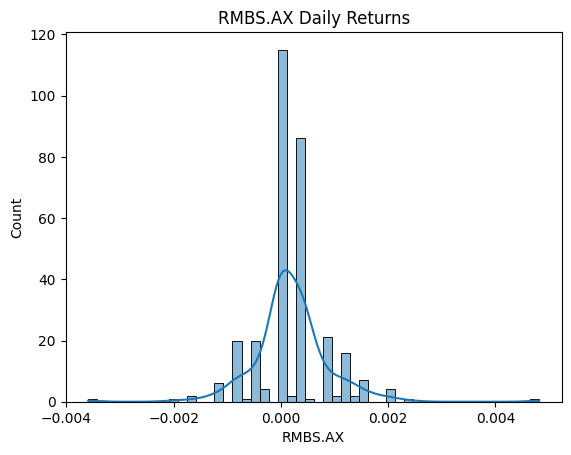

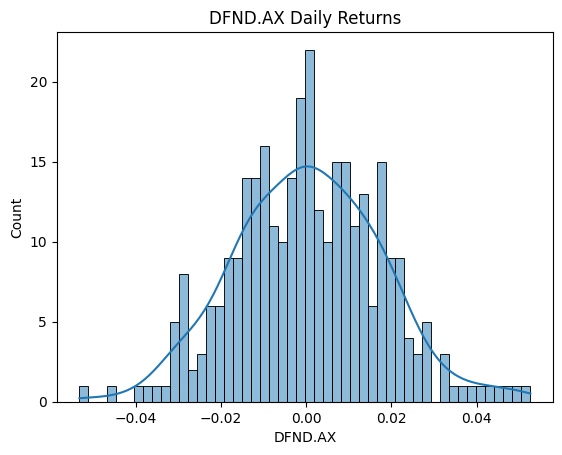

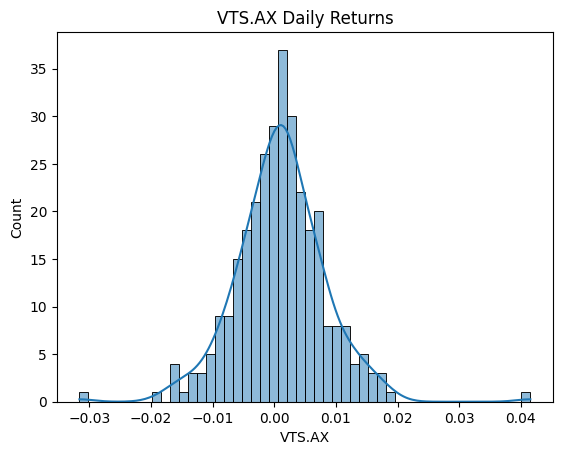

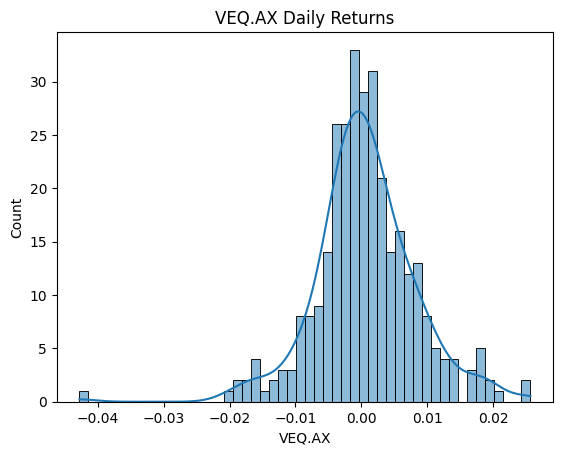

<Axes: xlabel='Ticker', ylabel='Ticker'>

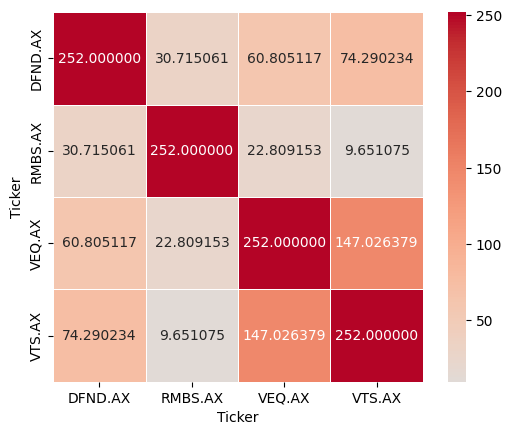

In [4]:
returns = data.pct_change()
returns = returns.dropna()

for tick in tickers:
    sns.histplot(data=returns, x=tick, kde=True, bins=50)
    plt.title(f'{tick} Daily Returns')
    plt.show()

corr_matrix = returns.corr() *252
cov_matrix = returns.cov() * 252



sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.6f',
    linewidth=0.5,
    square=True
)

In [5]:
stats_df = pd.DataFrame({
    'Mean': returns.mean(),
    'Std': returns.std(),
    'Skew': returns.apply(skew),
    'Excess Kurtosis': returns.apply(kurtosis),
    'JB p-value': [jarque_bera(returns[t].dropna())[1] for t in tickers],
    'Min': returns.min(),
    'Max': returns.max()
})

print("\nReturn Statistics:")
print(stats_df.round(6))


Return Statistics:
             Mean       Std      Skew  Excess Kurtosis  JB p-value       Min  \
Ticker                                                                         
DFND.AX  0.000411  0.017191  0.092885         0.202935    0.000000 -0.053161   
RMBS.AX  0.000193  0.000705  0.554886         8.294722    0.610435 -0.003593   
VEQ.AX   0.000599  0.007738 -0.289885         3.487633    0.000000 -0.042761   
VTS.AX   0.000989  0.007296  0.229299         3.666943    0.000000 -0.031610   

              Max  
Ticker             
DFND.AX  0.052632  
RMBS.AX  0.004814  
VEQ.AX   0.025613  
VTS.AX   0.041542  


In [6]:
TRADING_DAYS = 252
mean_returns = returns.mean() * TRADING_DAYS
cov_matrix = returns.cov() * TRADING_DAYS

print("\nAnnualized Expected Returns:")
print(mean_returns.round(4))



Annualized Expected Returns:
Ticker
DFND.AX    0.1036
RMBS.AX    0.0485
VEQ.AX     0.1510
VTS.AX     0.2493
dtype: float64



Max Sharpe Portfolio:
Return        0.1215
Volatility    0.0431
Sharpe        1.8191
Name: 364979, dtype: float64
RMBS.AX    0.0007
DFND.AX    0.6336
VTS.AX     0.0049
VEQ.AX     0.3609
Name: Max Sharpe Weights, dtype: float64

Minimum Volatility Portfolio:
Return        0.0547
Volatility    0.0124
Sharpe        0.9309
Name: 222224, dtype: float64
RMBS.AX    0.0003
DFND.AX    0.9515
VTS.AX     0.0363
VEQ.AX     0.0119
Name: Min Vol Weights, dtype: float64


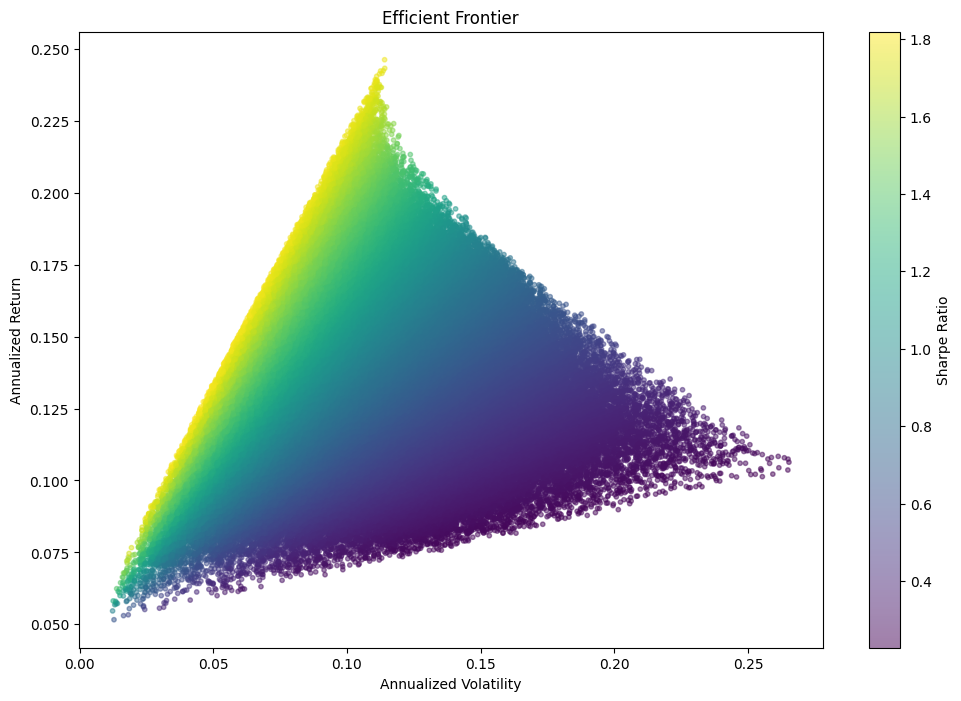

In [9]:
#monte carlo

iterations = 500000
rf_rate = 0.043173
n_assets = len(tickers)

results = np.zeros((3, iterations))
all_weights = np.zeros((iterations, n_assets))

for i in range(iterations):
    w = np.random.random(n_assets)
    w = w / np.sum(w)

    all_weights[i, :] = w

    port_return = np.dot(w, mean_returns)
    port_vol = np.sqrt(np.dot(w.T, np.dot(cov_matrix, w)))
    sharpe = (port_return - rf_rate) / port_vol

    results[0, i] = port_return
    results[1, i] = port_vol
    results[2, i] = sharpe

results_df = pd.DataFrame(results.T, columns=['Return', 'Volatility', 'Sharpe'])

max_sharpe_idx = results_df['Sharpe'].idxmax()
min_vol_idx = results_df['Volatility'].idxmin()

max_sharpe_port = results_df.loc[max_sharpe_idx]
min_vol_port = results_df.loc[min_vol_idx]

best_weights = pd.Series(all_weights[max_sharpe_idx], index=tickers, name='Max Sharpe Weights')
minvol_weights = pd.Series(all_weights[min_vol_idx], index=tickers, name='Min Vol Weights')

print("\nMax Sharpe Portfolio:")
print(max_sharpe_port.round(4))
print(best_weights.round(4))

print("\nMinimum Volatility Portfolio:")
print(min_vol_port.round(4))
print(minvol_weights.round(4))

plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    results_df['Volatility'],
    results_df['Return'],
    c=results_df['Sharpe'],
    cmap='viridis',
    alpha=0.5,
    s=10
)

cbar = plt.colorbar(scatter)
cbar.set_label('Sharpe Ratio')

plt.xlabel('Annualized Volatility')
plt.ylabel('Annualized Return')
plt.title('Efficient Frontier')

plt.show()